In [1]:
from IPython.core.display import Image
from typing import Literal

from langchain.chat_models import init_chat_model
from langchain_core.messages import AIMessage, HumanMessage
from langgraph.constants import START, END
from langgraph.graph import MessagesState, StateGraph

In [2]:
# 一、.准备父子的State
# 1.1.父State
class IntentState(MessagesState):
    intent: str  # 意图识别

# 1.2.子State
class WeatherState(MessagesState):
    val: str

In [3]:
from langchain.agents import create_agent
from langchain.tools import tool


# 二、定义子图 Subgraph

# 1.工具
@tool
def get_weather(city: str) -> str:
    """获取城市天气"""
    weather_data = {
        "北京": "晴天 25度",
        "上海": "多云 28度",
        "杭州": "小雨 22度",
    }
    return weather_data.get(city, f"未找到{city}的天气信息")

# 2.模型
model = init_chat_model(
    'deepseek-v4-flash',
    extra_body={'thinking': {'type': 'disabled'}}
)

# 3.使用LangChain的create_agent来创建一个子图
weather_agent = create_agent(
    model,
    tools=[get_weather],
    state_schema=WeatherState
)

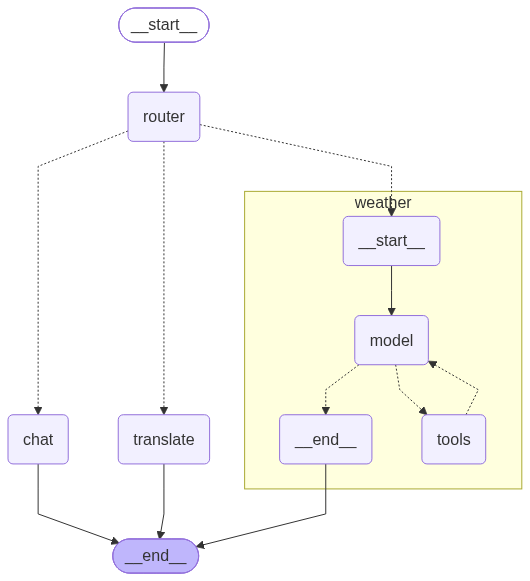

In [9]:
# 三、父Graph


# 1.定义模型
llm = init_chat_model(
    'deepseek-v4-flash',
    extra_body={'thinking': {'type': 'disabled'}}
)


# 2.定义Node
def intent_node(state: IntentState):
    message = f'''
    根据用户的请求判断用户意图，可选意图：weather、translate、chat。
    user_query: {state['messages'][-1].content}
    '''
    # 调用模型，结果是AIMessage
    response = llm.invoke(message)
    # 更新State
    return {"intent": response.text}

def chat_node(state: IntentState):
    # 闲聊，直接调用模型，生成回复，是AIMessage
    response = llm.invoke(state['messages'])
    return {"messages": [response]}

# def weather_node(state: IntentState):
#     # 天气查询，直接写死答案
#     return {"messages": [AIMessage("今天天气晴朗，温度25摄氏度")]}

# def weather_node(state: IntentState):
#     # 手动调用子图，传入消息
#     response = weather_agent.invoke({"messages": state['messages']})
#     return {"messages": [response['messages'][-1]]}

def translate_node(state: IntentState):
    message = f'''
    根据用户的要求翻译，直接返回翻译的内容，不要有任何解释
    user_query: {state['messages'][-1].content}
    '''
    # 调用模型，结果是AIMessage
    response = llm.invoke(message)
    return {"messages": [response]}

# 定义路由函数，根据意图路由到目标节点
def intent_route(state: IntentState) -> Literal["chat", "weather", "translate"]:
    return state['intent']

# 4.创建Graph，用Edge连接Node
builder = StateGraph(IntentState)

builder.add_node("router", intent_node)
builder.add_node("chat", chat_node)
builder.add_node("weather", weather_agent)
builder.add_node("translate", translate_node)

builder.add_edge(START, "router")
builder.add_conditional_edges("router", intent_route)
builder.add_edge("chat", END)
builder.add_edge("weather", END)
builder.add_edge("translate", END)

graph = builder.compile()

display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

In [5]:
query = "你好"
result = graph.invoke({"messages": [HumanMessage(query)]})
print(f"query: {query} , intent: {result['intent']}, result: {result['messages'][-1].text}")

query: 你好 , intent: chat, result: 你好！很高兴见到你，有什么我可以帮忙的吗？


In [6]:
query = "翻译一下: 虎哥 is handsome"
result = graph.invoke({"messages": [HumanMessage(query)]})
print(f"query: {query} , intent: {result['intent']}, result: {result['messages'][-1].text}")

query: 翻译一下: 虎哥 is handsome , intent: translate, result: 虎哥很帅


In [10]:
query = "今天杭州天气如何"
result = graph.invoke({"messages": [HumanMessage(query)]})
print(f"query: {query} , intent: {result['intent']}, result: {result['messages'][-1].text}")

query: 今天杭州天气如何 , intent: weather, result: 今天杭州是小雨天气，气温大约 22°C，出门记得带伞哦。


In [11]:
for m in result['messages']:
    m.pretty_print()

================================ Human Message =================================

今天杭州天气如何
================================== Ai Message ==================================

今天杭州是小雨天气，气温大约 22°C，出门记得带伞哦。
